In [1]:
import numpay as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
df=pd.read_csv("ford.csv")

In [3]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


In [4]:
df.shape

(17966, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17966 entries, 0 to 17965
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         17966 non-null  object 
 1   year          17966 non-null  int64  
 2   price         17966 non-null  int64  
 3   transmission  17966 non-null  object 
 4   mileage       17966 non-null  int64  
 5   fuelType      17966 non-null  object 
 6   tax           17966 non-null  int64  
 7   mpg           17966 non-null  float64
 8   engineSize    17966 non-null  float64
dtypes: float64(2), int64(4), object(3)
memory usage: 1.2+ MB


In [6]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,17966.000000,17966.000000,17966.000000,17966.000000,17966.000000,17966.000000
mean,2016.866470,12279.534844,23362.608761,113.329456,57.906980,1.350807
std,2.050336,4741.343657,19472.054349,62.012456,10.125696,0.432367
min,1996.000000,495.000000,1.000000,0.000000,20.800000,0.000000
25%,2016.000000,8999.000000,9987.000000,30.000000,52.300000,1.000000
50%,2017.000000,11291.000000,18242.500000,145.000000,58.900000,1.200000
75%,2018.000000,15299.000000,31060.000000,145.000000,65.700000,1.500000
max,2060.000000,54995.000000,177644.000000,580.000000,201.800000,5.000000


In [7]:
df.isnull().sum()

model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
dtype: int64

In [8]:
numeric_features = df.select_dtypes(exclude='object').columns.tolist()
categorical_features = df.select_dtypes(include='object').columns.tolist()

In [9]:
numeric_features

['year', 'price', 'mileage', 'tax', 'mpg', 'engineSize']

In [10]:
categorical_features

['model', 'transmission', 'fuelType']

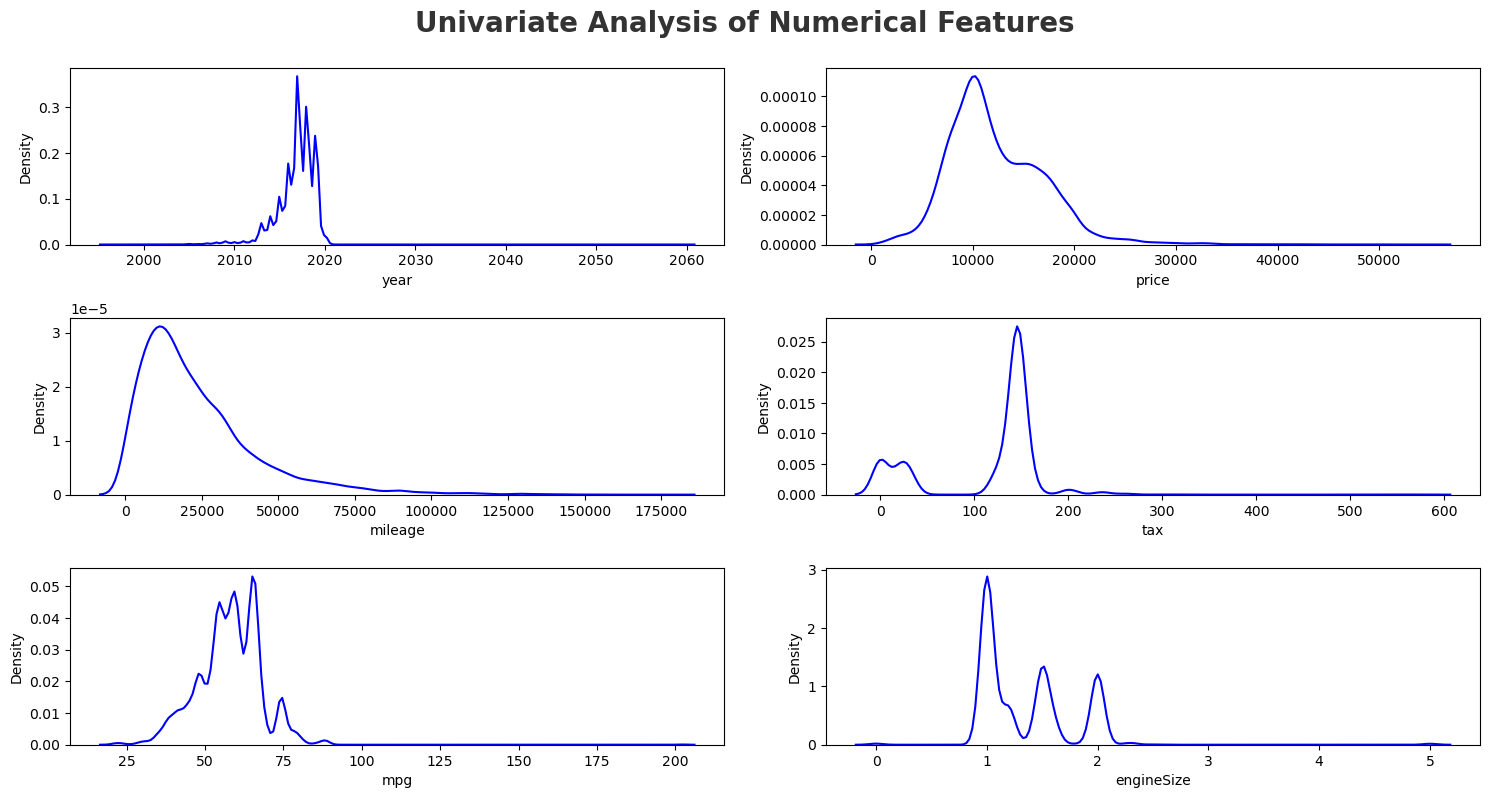

In [11]:
plt.figure(figsize=(15, 10))
plt.suptitle('Univariate Analysis of Numerical Features', fontsize=20, fontweight='bold', alpha=0.8, y=1.)

for i in range(0, len(numeric_features)):
    plt.subplot(4, 2, i+1)
    sns.kdeplot(x=df[numeric_features[i]], color='blue')
    plt.xlabel(numeric_features[i])
    plt.tight_layout()

In [12]:
categorical_columns = []

for i in categorical_features:

    print(f'{i}: {len(df[i].unique())}')

    if len(df[i].unique()) < 10:
        categorical_columns.append(i)

model: 24
transmission: 3
fuelType: 5


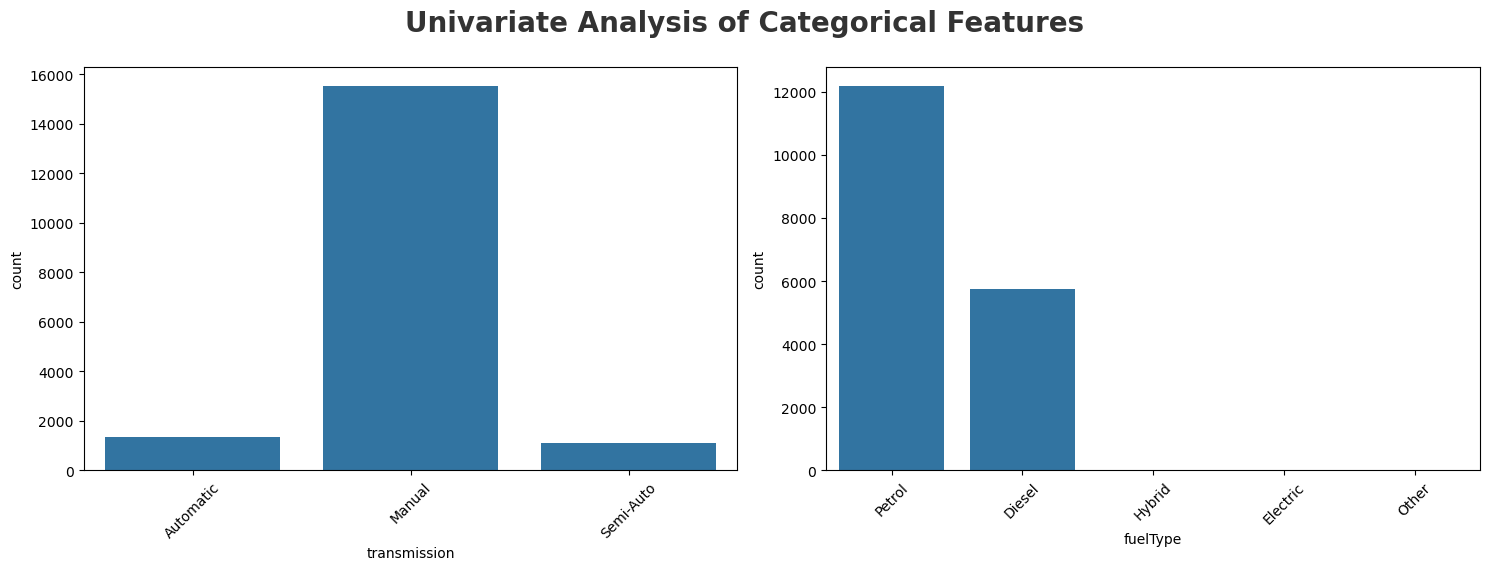

In [15]:
plt.figure(figsize=(15, 20))
plt.suptitle('Univariate Analysis of Categorical Features', fontsize=20, fontweight='bold', alpha=0.8, y=1.)
for i in range(0, len(categorical_columns)):
    plt.subplot(4, 2, i+1)
    sns.countplot(x=df[categorical_columns[i]])
    plt.xlabel(categorical_columns[i])
    plt.xticks(rotation=45)
    plt.tight_layout()

In [16]:
df.corr(numeric_only=True)

,year,price,mileage,tax,mpg,engineSize
year,1.000000,0.636009,-0.707818,0.298506,-0.022967,-0.137311
price,0.636009,1.000000,-0.530659,0.406857,-0.346419,0.411178
mileage,-0.707818,-0.530659,1.000000,-0.260451,0.120075,0.215035
tax,0.298506,0.406857,-0.260451,1.000000,-0.502980,0.184363
mpg,-0.022967,-0.346419,0.120075,-0.502980,1.000000,-0.260521
engineSize,-0.137311,0.411178,0.215035,0.184363,-0.260521,1.000000


<Axes: >

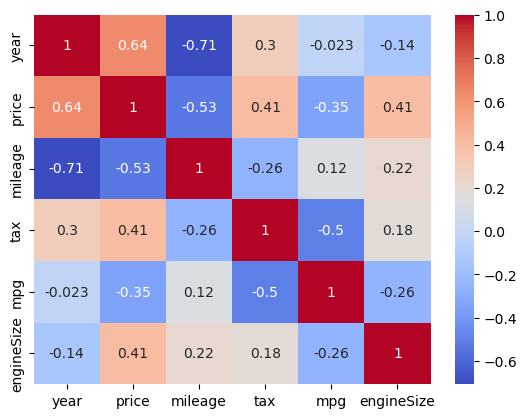

In [17]:
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap="coolwarm")

In [21]:
target_feature= 'price'

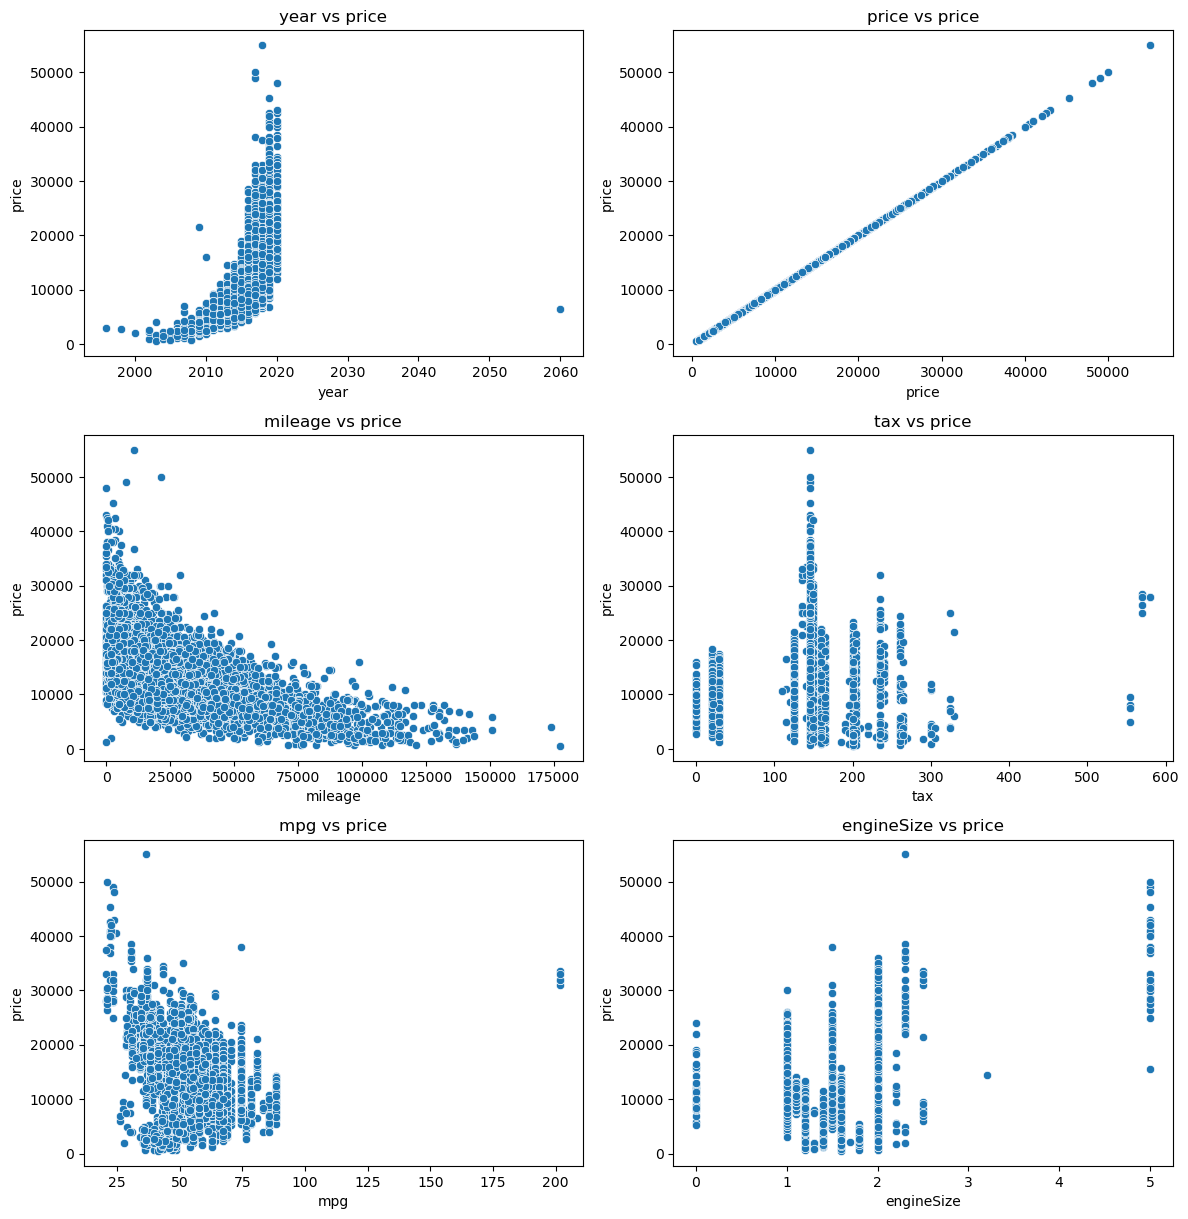

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

fig = plt.figure(figsize=(12, 24))

for i in range(len(numeric_features)):

    ax = plt.subplot(6, 2, i + 1)

    sns.scatterplot(
        data=df,
        x=numeric_features[i],
        y=target_feature,
        ax=ax
    )

    ax.set_title(
        f"{numeric_features[i]} vs {target_feature}"
    )

plt.tight_layout()
plt.show()

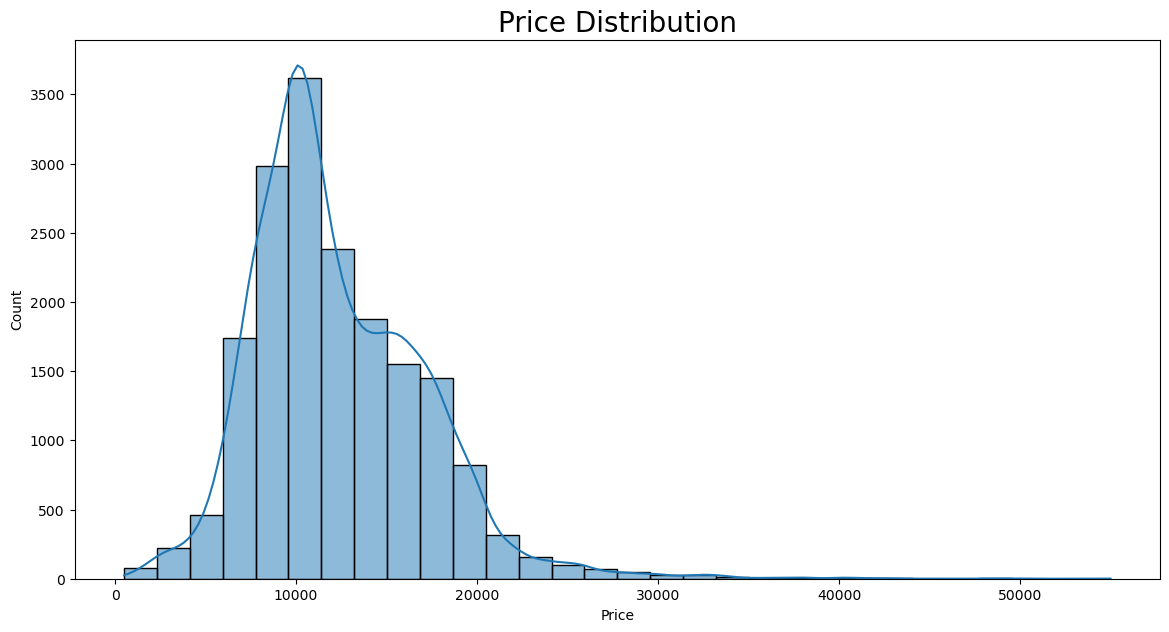

In [24]:
plt.figure(figsize=(14, 7))

sns.histplot(
    data=df,
    x='price',
    bins=30,
    kde=True
)

plt.title("Price Distribution", fontsize=20)
plt.xlabel("Price")
plt.ylabel("Count")

plt.show()


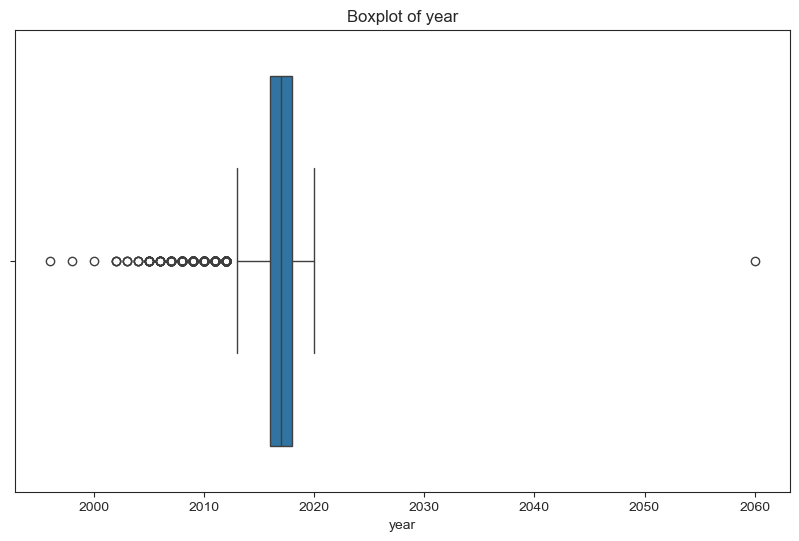

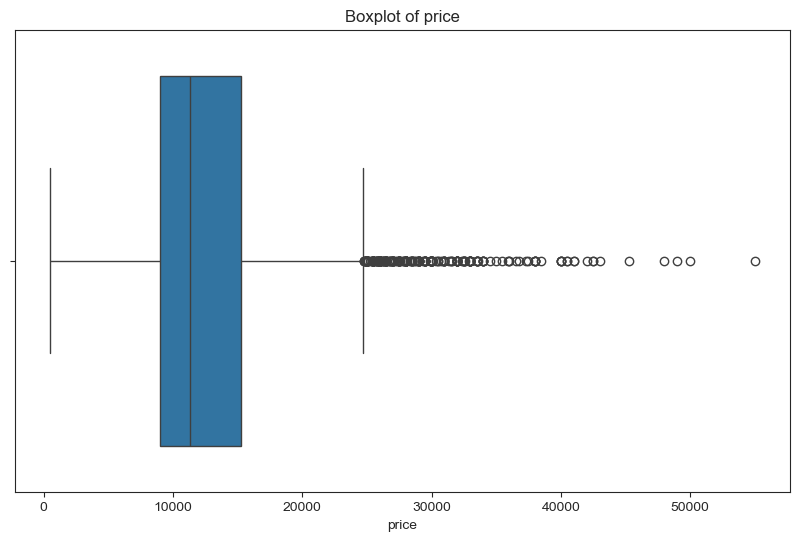

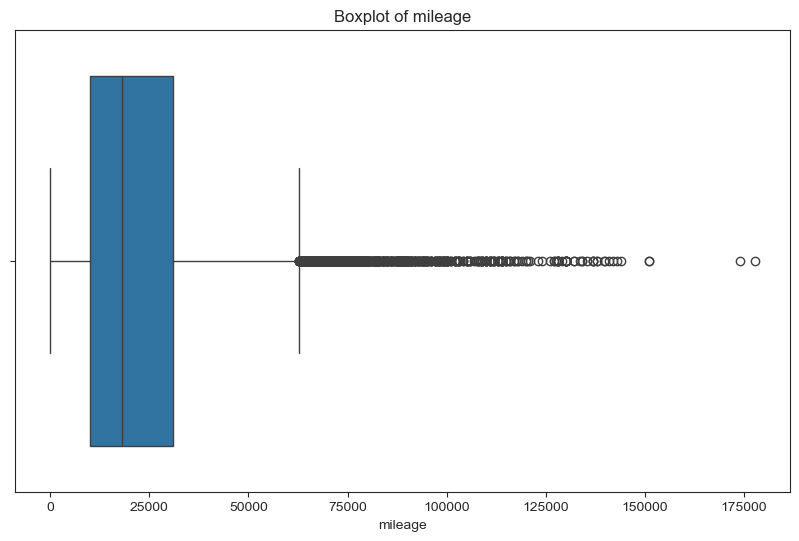

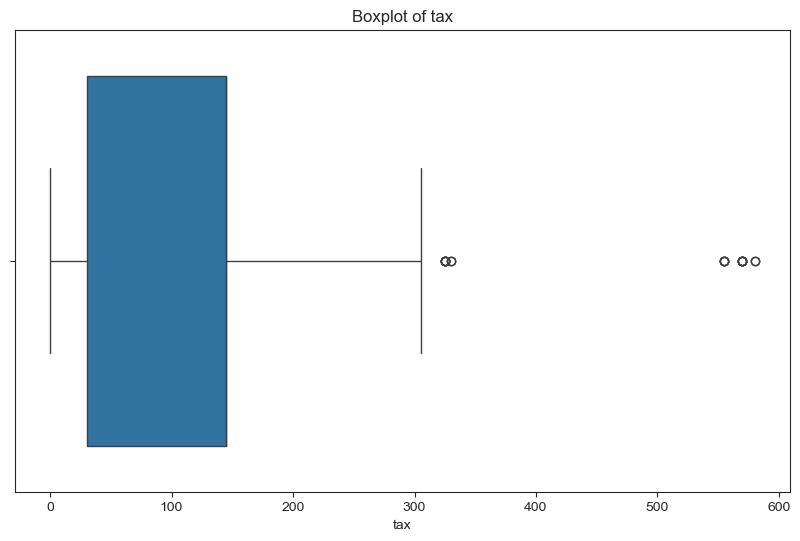

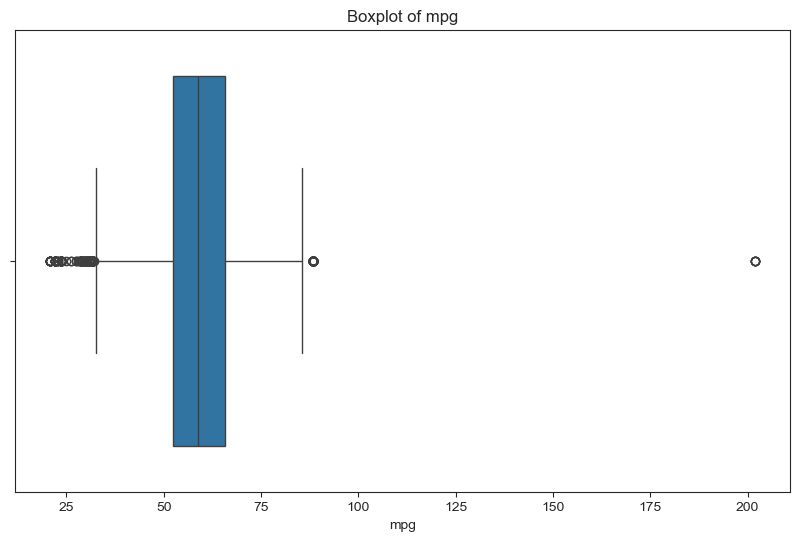

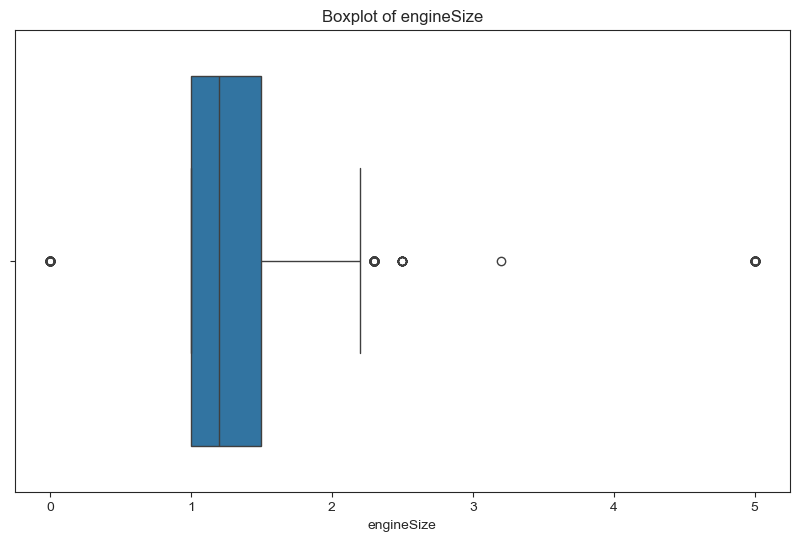

In [25]:
for i in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.set_style("ticks")

    ax = sns.boxplot(x=df[i])

    plt.title(f"Boxplot of {i}")
    plt.show()


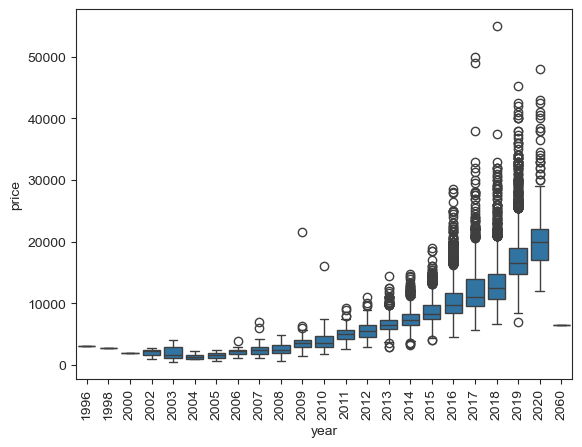

In [28]:
sns.boxplot(data=df,x="year",y="price")
plt.xticks(rotation=90)
plt.show()

<Axes: xlabel='mileage', ylabel='price'>

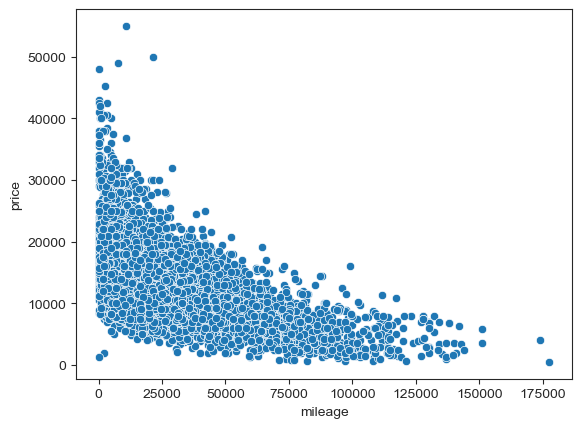

In [29]:
sns.scatterplot(x="mileage",y="price",data=df)

<Axes: xlabel='engineSize', ylabel='price'>

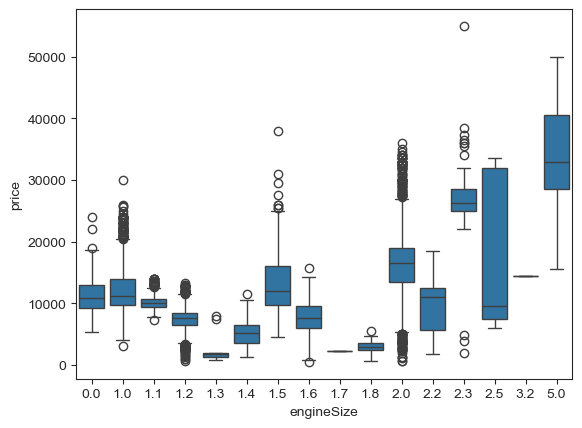

In [31]:
sns.boxplot(x="engineSize",y="price",data=df)

<Axes: xlabel='transmission', ylabel='price'>

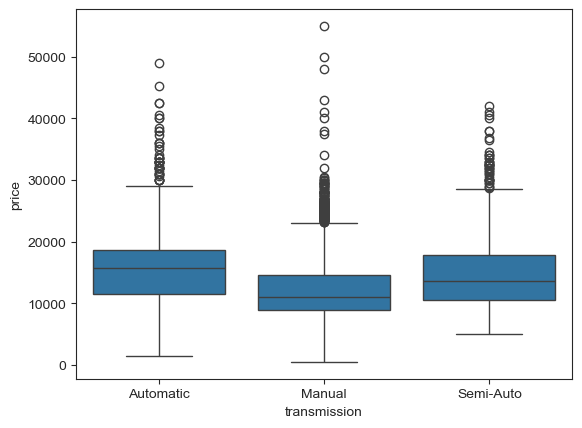

In [32]:
sns.boxplot(x="transmission",y="price",data=df)

<Axes: xlabel='fuelType', ylabel='price'>

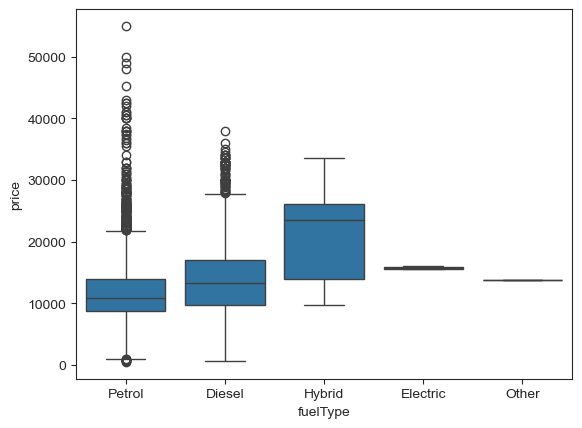

In [33]:
sns.boxplot(x="fuelType",y="price",data=df)

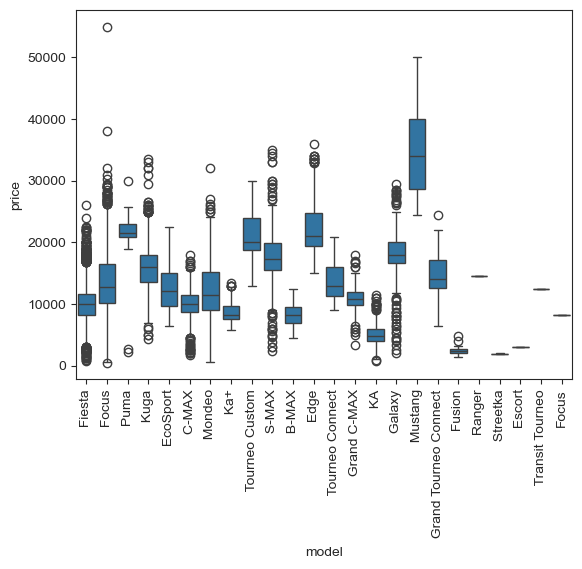

In [34]:
sns.boxplot(x="model",y="price",data=df)
plt.xticks(rotation=90)
plt.show()

In [44]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

In [36]:
x=df.drop(columns=["price"],axis=1)
y=df["price"]

In [39]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
numeric_features = x_train.select_dtypes(exclude="object").columns.tolist()
categorical_features = x_train.select_dtypes(include="object").columns.tolist()

numeric_features_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

categorical_features_pipeline = Pipeline([
    ("one_hot_encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_features_pipeline, numeric_features),
    ("categorical", categorical_features_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
     ("linear_regression", LinearRegression())
    # ("regressor", ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42))
    # ("random forest", RandomForestRegressor(n_estimators=100, random_state=42))
])

model.fit(x_train, y_train)

,steps,"[('preprocessor', ...), ('liner regession', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [47]:
model.predict(x_test)

array([ 6644.60445373,  9190.94328285,  9815.67574813, ...,
       30065.07502989,  9629.27244542, 15117.01285393], shape=(3594,))

In [51]:
model.named_steps["liner regession"].coef_

array([ 2164.70396985, -1303.93226618,   -67.52309856,  -766.6652894 ,
        1177.13185166, -4094.60060432, -2986.65622588, -2448.12861339,
        5342.18695   , 10177.66421034, -3018.93987876,  -931.24020289,
         -23.79623898,  2587.64615621, -2527.78431792,    65.93556852,
       -4558.95415426, -7051.74599917,  -352.78606702, -1212.48825736,
        7198.12833135,  3726.76933621,  1688.30015895,  2278.24140898,
         664.65095896,  -734.48244886,  2645.10897915, -2295.93825426,
       -4137.09079557,   188.19797325,  -254.66008828,    66.46211503,
       -2410.39198164,  -502.91718348,  6986.56905286, -1478.86012259,
       -2594.39976524])

In [52]:
model.named_steps["liner regession"].intercept_

np.float64(16878.60332485059)

In [54]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

y_pred = model.predict(x_test)

print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

R2 Score: 0.845842279725062
Mean Absolute Error: 1374.8108318948277
Mean Squared Error: 3454990.7936630663


In [55]:
import joblib

joblib.dump(model, "ford_model.pkl")

['ford_model.pkl']

In [56]:
df.columns

Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize'],
      dtype='object')

In [57]:
print(df["model"].nunique())
print(df["transmission"].nunique())
print(df["fuelType"].nunique())

24
3
5
